# quiz 2

## 實驗A

In [1]:
import sys
import importlib
from pathlib import Path
from IPython.display import display
from PIL import Image
from other_code import quiz2a as exp

importlib.reload(exp)

print("Python環境：", sys.executable)
print("目前工作目錄：", Path.cwd())
print("專案根目錄：", exp.PROJECT_ROOT)

cases, schema, validator = exp.load_assets()
system_prompt = exp.build_prompt(schema)

print("Benchmark筆數：", len(cases))

Python環境： /root/venvs/MMIP/bin/python
目前工作目錄： /root/MMIP/week9
專案根目錄： /root/MMIP/week9
Benchmark筆數： 10


### 載入模型

In [2]:
model, processor = exp.load_model()

print("模型載入完成：", exp.MODEL_ID)

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

模型載入完成： Qwen/Qwen2.5-VL-3B-Instruct


### 測試一筆

案例： case_01
使用者： 我今天收到這副耳機，打開就看到外殼破損，裡面的零件都露出來了，我想換一副新的。


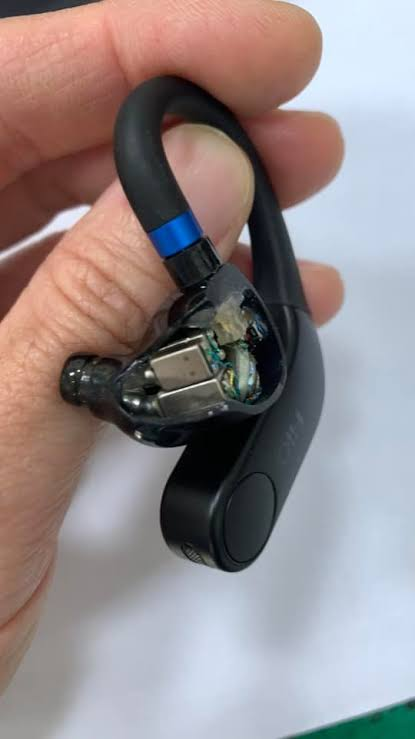

模型原始輸出：
{
  "status": "clarify",
  "department": null,
  "product": "耳機",
  "summary": "收到破損的耳機，需要換新。",
  "missing_fields": ["problem"],
  "reply": "請問您是哪個品牌和型號的耳機？另外，您是否有其他配件或包裝一起收到？"
}

耗時：3.36秒

格式檢查：
{'parsed_output': {'status': 'clarify', 'department': None, 'product': '耳機', 'summary': '收到破損的耳機，需要換新。', 'missing_fields': ['problem'], 'reply': '請問您是哪個品牌和型號的耳機？另外，您是否有其他配件或包裝一起收到？'}, 'json_valid': True, 'schema_valid': True, 'status_department_correct': True, 'validation_error': None}


In [14]:
case = cases[0]

print("案例：", case["id"])
print("使用者：", case["text"])

with Image.open(exp.PROJECT_ROOT / case["image"]) as img:
    display(img.copy())

preview = exp.generate_reply(model, processor, case, system_prompt)

print("模型原始輸出：")
print(preview["raw_output"])
print(f"\n耗時：{preview['elapsed_seconds']:.2f}秒")

evaluation = exp.evaluate_output(preview["raw_output"], case["expected"], validator)

print("\n格式檢查：")
print(evaluation)

### 正式執行10筆benchmark

In [17]:
report, result_path = exp.run_benchmark(model, processor, cases, schema, validator)

display(exp.summarize(report))
print("結果檔：", result_path)

case_01：Schema=True，平均顯存=7.10 GiB
case_02：Schema=True，平均顯存=7.10 GiB
case_03：Schema=True，平均顯存=7.10 GiB
case_04：Schema=True，平均顯存=7.10 GiB
case_05：Schema=True，平均顯存=7.11 GiB
case_06：Schema=True，平均顯存=7.10 GiB
case_07：Schema=True，平均顯存=7.10 GiB
case_08：Schema=True，平均顯存=7.11 GiB
case_09：Schema=True，平均顯存=7.11 GiB
case_10：Schema=True，平均顯存=7.10 GiB
========== 自動評估 ==========
案例數：10
推論失敗數： 0
JSON可解析率：100%
Schema通過率：100%
狀態與部門符合率：60%
取得輸出的平均耗時：3.38 秒（10/10筆有資料）
各筆平均顯存的平均：7.10 GiB（10/10筆有資料）
所有案例最高顯存峰值：7.35 GiB

========== 人工內容評分 ==========
已評分：0/10筆
尚未評分：10筆
內容通過率：尚未評分

========== 失敗案例 ==========
case_02：status或department不符合預期
case_05：status或department不符合預期
case_06：status或department不符合預期
case_08：status或department不符合預期


,id,json_valid,schema_valid,status_department_correct,elapsed_seconds,gpu_memory_mean_gib,gpu_memory_peak_gib,behavior_pass,behavior_notes
0,case_01,True,True,True,3.479167,7.104106,7.345823,None,
1,case_02,True,True,False,3.168997,7.101788,7.295196,None,
2,case_03,True,True,True,3.704921,7.099895,7.287683,None,
3,case_04,True,True,True,3.281504,7.102140,7.294874,None,
4,case_05,True,True,False,3.709452,7.108332,7.328206,None,
5,case_06,True,True,False,4.022947,7.099870,7.291651,None,
6,case_07,True,True,True,3.393561,7.100599,7.283964,None,
7,case_08,True,True,False,2.963894,7.106949,7.345331,None,
8,case_09,True,True,True,3.040539,7.108070,7.344441,None,
9,case_10,True,True,True,3.038408,7.097871,7.286325,None,


結果檔： /root/MMIP/week9/result/quiz2/experiment_a_1794573599107007839.json


### 逐筆查看模型回答

In [36]:
index = 9
row = report["cases"][index]

print("案例：", row["id"])
print("使用者：", row["text"])

print("\n模型輸出：")
print(row["raw_output"])

print("\n必要行為：")
for item in row["expected"]["required_behavior"]:
    print("-", item)

print("\n禁止行為：")
for item in row["expected"].get("forbidden_behavior", []):
    print("-", item)

案例： case_10
使用者： 我收到的耳機外殼破掉了，想換貨，這是商品照片。

模型輸出：
{
  "status": "clarify",
  "department": null,
  "product": "耳機外殼",
  "summary": "收到的商品外殼破掉，想要換貨。",
  "missing_fields": ["order_id"],
  "reply": "請提供您的訂單編號以便我們確認您的退換貨申請。"
}

必要行為：
- 辨識實際圖片為鍵盤
- 指出圖片商品與耳機敘述不一致
- 請使用者確認商品或重新上傳正確圖片

禁止行為：
- 將鍵盤照片描述成破損耳機
- 忽略圖文矛盾直接確認換貨分流


### 人工評分後存檔

In [37]:
# True＝通過，False＝不通過，None＝尚未評分
score = False
notes = ("未辨識圖片為鍵盤，未指出圖片與耳機敘述不一致；"
    "沒有請使用者確認商品或重新上傳正確圖片，僅索取訂單編號。")

# 例如：
# score = False
# notes = "沒有請使用者確認摘要，就宣稱已完成派單。"

if score is not None and not isinstance(score, bool):
    raise ValueError("score只能填True、False或None")

report["cases"][index]["behavior_pass"] = score
report["cases"][index]["behavior_notes"] = notes

exp.save_report(report, result_path)

print("已儲存：", report["cases"][index]["id"])
display(exp.summarize(report))

已儲存： case_10
========== 自動評估 ==========
案例數：10
推論失敗數： 0
JSON可解析率：100%
Schema通過率：100%
狀態與部門符合率：60%
取得輸出的平均耗時：3.38 秒（10/10筆有資料）
各筆平均顯存的平均：7.10 GiB（10/10筆有資料）
所有案例最高顯存峰值：7.35 GiB

========== 人工內容評分 ==========
已評分：10/10筆
尚未評分：0筆
內容通過：1筆
內容不通過：9筆
內容通過率：10%

========== 失敗案例 ==========
case_01：內容不通過：有記錄耳機破損與換貨需求，但未請使用者確認摘要；問題已明確描述，missing_fields仍填problem。
case_02：status或department不符合預期；內容不通過：正確辨識手機螢幕破裂與退貨需求，但未確認摘要就輸出route；回覆要求訂單編號，missing_fields卻為空。
case_03：內容不通過：有記錄訂鍵盤卻收到滑鼠，但未記錄換貨需求及請求確認摘要；重複追問已提供的商品資訊，product卻填為字串「無」。
case_04：內容不通過：未提醒檢查接收器收納位置，摘要將疑似缺件寫成確定缺件；自行指定商品型號，且索取訂單編號卻未列入missing_fields。
case_05：status或department不符合預期；內容不通過：正確辨識藍牙連線問題與技術支援方向，但未追問或確認摘要就輸出route；僅提供一般建議，未利用截圖中的驗證碼提示。
case_06：status或department不符合預期；內容不通過：正確辨識USB裝置無法辨識的錯誤，但未追問裝置種類與使用情況，也未確認摘要就輸出route；missing_fields未列出待補資訊。
case_08：status或department不符合預期；內容不通過：正確辨識包裹配送中及物流查詢需求，但未索取訂單編號等必要資訊，也未確認摘要就輸出route；回覆僅重述配送查詢需求。
case_09：內容不通過：正確理解包裹到店但未收到取貨通知，並追問查詢資訊；但missing_fields為空，未記錄回覆中要求的訂單編號與聯絡電話。
case_10：內容不通過：未辨識圖片為鍵盤，未指出圖片與耳

,id,json_valid,schema_valid,status_department_correct,elapsed_seconds,gpu_memory_mean_gib,gpu_memory_peak_gib,behavior_pass,behavior_notes
0,case_01,True,True,True,3.479167,7.104106,7.345823,False,有記錄耳機破損與換貨需求，但未請使用者確認摘要；問題已明確描述，missing_fields...
1,case_02,True,True,False,3.168997,7.101788,7.295196,False,正確辨識手機螢幕破裂與退貨需求，但未確認摘要就輸出route；回覆要求訂單編號，missin...
2,case_03,True,True,True,3.704921,7.099895,7.287683,False,有記錄訂鍵盤卻收到滑鼠，但未記錄換貨需求及請求確認摘要；重複追問已提供的商品資訊，produ...
3,case_04,True,True,True,3.281504,7.102140,7.294874,False,未提醒檢查接收器收納位置，摘要將疑似缺件寫成確定缺件；自行指定商品型號，且索取訂單編號卻未列...
4,case_05,True,True,False,3.709452,7.108332,7.328206,False,正確辨識藍牙連線問題與技術支援方向，但未追問或確認摘要就輸出route；僅提供一般建議，未利...
5,case_06,True,True,False,4.022947,7.099870,7.291651,False,正確辨識USB裝置無法辨識的錯誤，但未追問裝置種類與使用情況，也未確認摘要就輸出route；...
6,case_07,True,True,True,3.393561,7.100599,7.283964,True,正確辨識鍵盤，追問具體問題，並在資訊不足時保留分流判斷。
7,case_08,True,True,False,2.963894,7.106949,7.345331,False,正確辨識包裹配送中及物流查詢需求，但未索取訂單編號等必要資訊，也未確認摘要就輸出route；...
8,case_09,True,True,True,3.040539,7.108070,7.344441,False,正確理解包裹到店但未收到取貨通知，並追問查詢資訊；但missing_fields為空，未記錄...
9,case_10,True,True,True,3.038408,7.097871,7.286325,False,未辨識圖片為鍵盤，未指出圖片與耳機敘述不一致；沒有請使用者確認商品或重新上傳正確圖片，僅索取...


## 實驗B

### 匯入與檢查資料

In [3]:
from other_code import quiz2a as a
from other_code import quiz2b as b

cases, schema, validator = a.load_assets()
training_rows = b.load_training_data(validator)

print("Benchmark筆數：", len(cases))
print("SFT樣本數：", len(training_rows))

Benchmark筆數： 10
SFT樣本數： 15


### 訓練

In [4]:
model_b, processor_b, adapter_dir = b.train_sft(epochs=3, learning_rate=1e-4)

SFT樣本數： 15
不同圖片數： 5


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

trainable params: 3,686,400 || all params: 3,758,309,376 || trainable%: 0.0981
第一筆輸入token數： 1099
第一筆答案token數： 96


The model is already on multiple devices. Skipping the move to device specified in `args`.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


開始SFT＋LoRA訓練


Step,Training Loss
1,1.271500
2,1.279300
3,1.218200
4,1.314200
5,1.028000
6,1.405900
7,1.165500
8,1.240800
9,1.264900
10,1.091800


訓練完成
LoRA儲存位置： /root/MMIP/week9/result/quiz2/B_sft_training_1794577924200378533/adapter


### 測試一筆

In [5]:
preview_b = a.generate_reply(model_b, processor_b, cases[0], a.build_prompt(schema))

print(preview_b["raw_output"])

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{
  "status": "clarify",
  "department": null,
  "product": "耳機",
  "summary": "客戶反映收到的耳機外殼破損，內有零件露出。",
  "missing_fields": ["problem"],
  "reply": "請問您是哪一間店家購買的這副耳機？我們可以幫您確認是否屬於退換貨範疇。"
}


### 正式執行10筆benchmark

In [6]:
report_b, result_path_b = b.run_benchmark(model_b, processor_b, cases, schema, validator, adapter_dir)

display(a.summarize(report_b))
print("B結果檔：", result_path_b)

case_01：Schema=True，平均顯存=14.10 GiB
case_02：Schema=True，平均顯存=14.09 GiB
case_03：Schema=True，平均顯存=14.09 GiB
case_04：Schema=True，平均顯存=14.09 GiB
case_05：Schema=True，平均顯存=14.10 GiB
case_06：Schema=True，平均顯存=14.09 GiB
case_07：Schema=True，平均顯存=14.09 GiB
case_08：Schema=True，平均顯存=14.10 GiB
case_09：Schema=True，平均顯存=14.10 GiB
case_10：Schema=True，平均顯存=14.09 GiB
========== 自動評估 ==========
案例數：10
推論失敗數： 0
JSON可解析率：100%
Schema通過率：100%
狀態與部門符合率：90%
取得輸出的平均耗時：5.19 秒（10/10筆有資料）
各筆平均顯存的平均：14.09 GiB（10/10筆有資料）
所有案例最高顯存峰值：14.34 GiB

========== 人工內容評分 ==========
已評分：0/10筆
尚未評分：10筆
內容通過率：尚未評分

========== 失敗案例 ==========
case_08：status或department不符合預期


,id,json_valid,schema_valid,status_department_correct,elapsed_seconds,gpu_memory_mean_gib,gpu_memory_peak_gib,behavior_pass,behavior_notes
0,case_01,True,True,True,5.309769,14.100296,14.337050,None,
1,case_02,True,True,True,5.090372,14.093129,14.286757,None,
2,case_03,True,True,True,5.449620,14.092917,14.280342,None,
3,case_04,True,True,True,4.698099,14.091599,14.287967,None,
4,case_05,True,True,True,6.080851,14.097917,14.320111,None,
5,case_06,True,True,True,4.962006,14.091128,14.284028,None,
6,case_07,True,True,True,4.791754,14.090291,14.275513,None,
7,case_08,True,True,False,5.183867,14.099024,14.337544,None,
8,case_09,True,True,True,6.043333,14.099293,14.336669,None,
9,case_10,True,True,True,4.273375,14.090599,14.279408,None,


B結果檔： /root/MMIP/week9/result/quiz2/B_sft_1794578007677758528.json


### 逐筆查看模型回答

In [25]:
index = 9
row = report_b["cases"][index]

print("案例：", row["id"])
print("使用者：", row["text"])

print("\n模型輸出：")
print(row["raw_output"])

print("\n必要行為：")
for item in row["expected"]["required_behavior"]:
    print("-", item)

print("\n禁止行為：")
for item in row["expected"].get("forbidden_behavior", []):
    print("-", item)

案例： case_10
使用者： 我收到的耳機外殼破掉了，想換貨，這是商品照片。

模型輸出：
{
  "status": "clarify",
  "department": null,
  "product": "耳機外殼",
  "summary": "收到的商品外殼破掉，想要換貨。",
  "missing_fields": ["order_id"],
  "reply": "請提供您的訂單編號，以便我們確認您的換貨申請。"
}

必要行為：
- 辨識實際圖片為鍵盤
- 指出圖片商品與耳機敘述不一致
- 請使用者確認商品或重新上傳正確圖片

禁止行為：
- 將鍵盤照片描述成破損耳機
- 忽略圖文矛盾直接確認換貨分流


### 人工評分後存檔

In [26]:
score = False
notes = ("未辨識圖片為鍵盤，未指出圖片與耳機敘述不一致；"
    "沒有請使用者確認商品或重新上傳正確圖片，僅索取訂單編號。")

if score is not None and not isinstance(score, bool):
    raise ValueError("score只能填True、False或None")

report_b["cases"][index]["behavior_pass"] = score
report_b["cases"][index]["behavior_notes"] = notes

a.save_report(report_b, result_path_b)
display(a.summarize(report_b))

========== 自動評估 ==========
案例數：10
推論失敗數： 0
JSON可解析率：100%
Schema通過率：100%
狀態與部門符合率：90%
取得輸出的平均耗時：5.19 秒（10/10筆有資料）
各筆平均顯存的平均：14.09 GiB（10/10筆有資料）
所有案例最高顯存峰值：14.34 GiB

========== 人工內容評分 ==========
已評分：10/10筆
尚未評分：0筆
內容通過：0筆
內容不通過：10筆
內容通過率：0%

========== 失敗案例 ==========
case_01：內容不通過：正確記錄耳機外殼破損與零件露出，但漏記換貨需求，未請使用者確認摘要；問題已明確卻將problem列為缺項，且與購買店家的追問不一致。
case_02：內容不通過：正確記錄螢幕破裂與退貨需求，且未提前分流，但未請使用者確認摘要；將已知問題與處理需求列為缺項，卻未記錄回覆中要求的地區、聯絡方式與訂單編號。
case_03：內容不通過：有記錄訂鍵盤卻收到滑鼠，但漏記換貨需求且未確認摘要；已知商品資訊卻將product填為字串「無」，索取訂單編號卻未將order_id列入missing_fields。
case_04：內容不通過：未提醒檢查接收器收納位置，未釐清是否確實缺件；已知希望補寄卻將requested_action列為缺項，並自行指定缺乏依據的商品型號。
case_05：內容不通過：正確辨識藍牙連線失敗且未提前分流，但未追問或確認摘要，也未利用驗證碼提示；錯誤要求耳機與手機連接同一Wi-Fi網路。
case_06：內容不通過：正確辨識USB裝置無法辨識，並合理追問品牌、型號與Windows版本；但問題已明確，missing_fields仍填problem，未對應實際追問內容。
case_07：內容不通過：正確辨識鍵盤並保留分流判斷，但追問混入「滑鼠無法移動」的不相關情境，未維持鍵盤案件的商品一致性。
case_08：status或department不符合預期；內容不通過：未索取訂單編號等查詢資訊，也未確認摘要就輸出route；混合最新配送中與較早到店紀錄，未釐清狀態順序，回覆僅提醒取件，未推進配送查詢。
case_09：內容不通過：摘要正確記錄包裹到店但未收到通知，回覆卻引用較舊的即將送店狀態，前後矛盾；重複

,id,json_valid,schema_valid,status_department_correct,elapsed_seconds,gpu_memory_mean_gib,gpu_memory_peak_gib,behavior_pass,behavior_notes
0,case_01,True,True,True,5.309769,14.100296,14.337050,False,正確記錄耳機外殼破損與零件露出，但漏記換貨需求，未請使用者確認摘要；問題已明確卻將probl...
1,case_02,True,True,True,5.090372,14.093129,14.286757,False,正確記錄螢幕破裂與退貨需求，且未提前分流，但未請使用者確認摘要；將已知問題與處理需求列為缺項...
2,case_03,True,True,True,5.449620,14.092917,14.280342,False,有記錄訂鍵盤卻收到滑鼠，但漏記換貨需求且未確認摘要；已知商品資訊卻將product填為字串「...
3,case_04,True,True,True,4.698099,14.091599,14.287967,False,未提醒檢查接收器收納位置，未釐清是否確實缺件；已知希望補寄卻將requested_actio...
4,case_05,True,True,True,6.080851,14.097917,14.320111,False,正確辨識藍牙連線失敗且未提前分流，但未追問或確認摘要，也未利用驗證碼提示；錯誤要求耳機與手機...
5,case_06,True,True,True,4.962006,14.091128,14.284028,False,正確辨識USB裝置無法辨識，並合理追問品牌、型號與Windows版本；但問題已明確，miss...
6,case_07,True,True,True,4.791754,14.090291,14.275513,False,正確辨識鍵盤並保留分流判斷，但追問混入「滑鼠無法移動」的不相關情境，未維持鍵盤案件的商品一致性。
7,case_08,True,True,False,5.183867,14.099024,14.337544,False,未索取訂單編號等查詢資訊，也未確認摘要就輸出route；混合最新配送中與較早到店紀錄，未釐清...
8,case_09,True,True,True,6.043333,14.099293,14.336669,False,摘要正確記錄包裹到店但未收到通知，回覆卻引用較舊的即將送店狀態，前後矛盾；重複詢問已知資訊，...
9,case_10,True,True,True,4.273375,14.090599,14.279408,False,未辨識圖片為鍵盤，未指出圖片與耳機敘述不一致；沒有請使用者確認商品或重新上傳正確圖片，僅索取...


## 實驗C

### 匯入與檢查資料

In [2]:
from other_code import quiz2a as a
from other_code import quiz2c as c

cases, schema, validator = a.load_assets()

model_c, processor_c = a.load_model()

print("C使用原始模型：", a.MODEL_ID)

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

C使用原始模型： Qwen/Qwen2.5-VL-3B-Instruct


In [3]:
import importlib

importlib.reload(a)
importlib.reload(c)

preview_c = c.generate_reply(
    model_c,
    processor_c,
    cases[0],
    a.build_prompt(schema),
)

print("最後token：", preview_c["last_token_id"])
print("輸出token數：", preview_c["output_tokens"])
print("最後80字：", repr(preview_c["raw_output"][-80:]))

print(a.evaluate_output(
    preview_c["raw_output"],
    cases[0]["expected"],
    validator,
))

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


最後token： 151645
輸出token數： 57
最後80字： ' "耳機", "summary": "收到破損的耳機，需要換新", "missing_fields": [], "reply": "您的            '
{'parsed_output': None, 'json_valid': False, 'schema_valid': False, 'status_department_correct': False, 'validation_error': 'Unterminated string starting at: line 1 column 121 (char 120)'}


### 測試一筆

In [4]:
preview_c = c.generate_reply(model_c, processor_c, cases[0], a.build_prompt(schema))

print(preview_c["raw_output"])

print(
    a.evaluate_output(
        preview_c["raw_output"],
        cases[0]["expected"],
        validator,
    )
)

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{
  "status": "clarify",
  "department": null,
  "product": "耳機",
  "summary": "收到破損的耳機，需要換新耳機",
  "missing_fields": ["problem"],
  "reply": "您的			
{'parsed_output': None, 'json_valid': False, 'schema_valid': False, 'status_department_correct': False, 'validation_error': 'Invalid control character at: line 7 column 15 (char 144)'}


### 正式執行10筆benchmark

In [5]:
report_c, result_path_c = c.run_benchmark(model_c, processor_c, cases, schema, validator)

display(a.summarize(report_c))
print("C結果檔：", result_path_c)

case_01：Schema=False，平均顯存=14.03 GiB
case_02：Schema=False，平均顯存=14.02 GiB
case_03：Schema=False，平均顯存=14.02 GiB
case_04：Schema=False，平均顯存=14.02 GiB
case_05：Schema=False，平均顯存=14.02 GiB
case_06：Schema=False，平均顯存=14.02 GiB
case_07：Schema=False，平均顯存=14.02 GiB
case_08：Schema=False，平均顯存=14.02 GiB
case_09：Schema=False，平均顯存=14.03 GiB
case_10：Schema=False，平均顯存=14.02 GiB
========== 自動評估 ==========
案例數：10
推論失敗數： 0
JSON可解析率：0%
Schema通過率：0%
狀態與部門符合率：0%
取得輸出的平均耗時：7.47 秒（10/10筆有資料）
各筆平均顯存的平均：14.02 GiB（10/10筆有資料）
所有案例最高顯存峰值：14.29 GiB

========== 人工內容評分 ==========
已評分：0/10筆
尚未評分：10筆
內容通過率：尚未評分

========== 失敗案例 ==========
case_01：結構錯誤：Invalid control character at: line 7 column 15 (char 144)
case_02：結構錯誤：Invalid control character at: line 5 column 18 (char 91)
case_03：結構錯誤：Invalid control character at: line 5 column 24 (char 88)
case_04：結構錯誤：Invalid control character at: line 7 column 14 (char 188)
case_05：結構錯誤：Invalid control character at: line 7 column 14 (char 143)
case_06：結構錯誤：Invalid control character 

,id,json_valid,schema_valid,status_department_correct,elapsed_seconds,gpu_memory_mean_gib,gpu_memory_peak_gib,behavior_pass,behavior_notes
0,case_01,False,False,False,8.444251,14.027480,14.289311,None,
1,case_02,False,False,False,6.385214,14.016665,14.237028,None,
2,case_03,False,False,False,6.812136,14.017459,14.230353,None,
3,case_04,False,False,False,8.580422,14.023434,14.239045,None,
4,case_05,False,False,False,7.849768,14.024309,14.270298,None,
5,case_06,False,False,False,8.849874,14.023754,14.234074,None,
6,case_07,False,False,False,7.262156,14.017119,14.226467,None,
7,case_08,False,False,False,5.664429,14.016424,14.289537,None,
8,case_09,False,False,False,8.308878,14.026430,14.289209,None,
9,case_10,False,False,False,6.504227,14.015817,14.228935,None,


C結果檔： /root/MMIP/week9/result/quiz2/C_decoding_1794580527107654963.json


### 逐筆查看模型回答

In [ ]:
index = 0
row = report_c["cases"][index]

print("案例：", row["id"])
print("使用者：", row["text"])

print("\n模型輸出：")
print(row["raw_output"])

print("\n必要行為：")
for item in row["expected"]["required_behavior"]:
    print("-", item)

print("\n禁止行為：")
for item in row["expected"].get("forbidden_behavior", []):
    print("-", item)

### 人工評分後存檔

In [ ]:
score = False
notes = ("未辨識圖片為鍵盤，未指出圖片與耳機敘述不一致；"
    "沒有請使用者確認商品或重新上傳正確圖片，僅索取訂單編號。")

if score is not None and not isinstance(score, bool):
    raise ValueError("score只能填True、False或None")

report_c["cases"][index]["behavior_pass"] = score
report_c["cases"][index]["behavior_notes"] = notes

a.save_report(report_c, result_path_c)
display(a.summarize(report_c))

# quiz 3
